# PROJETC-2
## HOUSE PRICE PREDICTION



## About the Project

House Price Prediction is a Machine Learning project that predicts the price of a house based on various factors such as location, size, number of bedrooms, bathrooms, overall quality, and year of construction.

The project uses Python and machine learning algorithms to analyze historical housing data and estimate house prices. The dataset is processed using libraries such as Pandas and NumPy, while Matplotlib and Seaborn are used for data visualization.

Machine learning algorithms such as Linear Regression and Random Forest Regressor are trained to identify patterns in the data and make price predictions. The performance of the models is evaluated using metrics such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

The main objective of this project is to develop a predictive model that helps users estimate house prices based on property features. It can assist buyers, sellers, and real estate professionals in making informed decisions.

This project provides practical knowledge of data preprocessing, exploratory data analysis, feature selection, machine learning model training, evaluation, and prediction.

## Objectives

1. To analyze housing data and identify important factors affecting house prices.
2. To preprocess and clean the dataset for machine learning.
3. To build and train machine learning models for house price prediction.
4. To evaluate model performance using appropriate regression metrics.
5. To predict house prices based on property characteristics.

## Technologies Used

- **Programming Language:** Python
- **Platform:** Jupyter Nootbook
- **Libraries:** Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn
- **Machine Learning Algorithms:** Linear Regression and Random Forest Regressor
- **Dataset:** House Prices: Advanced Regression Techniques (Kaggle)

## Conclusion

The House Price Prediction project demonstrates how machine learning can be used to estimate property prices using historical data. By analyzing different housing features and comparing predictive models, the project provides insights into the factors influencing house prices. It also offers practical experience in developing and evaluating a machine learning model for a real-world problem.

In [1]:
## Import necessary python libraries----
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load the data into Python

In [2]:
## import data sets (Bengaluru_House_Data.csv)
df=pd.read_csv("Bengaluru_House_Data.csv")

### Fetching some necessary and basic information

In [3]:
## Print basic Information from the data sets(Bengaluru_House_Data)

print("Display First 5 rows from the data:") 
df.head()

Display First 5 rows from the data:


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [4]:
print ("Display data type of each columns from the given data set")
df.info()

Display data type of each columns from the given data set
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [5]:
print ("Disply shape of the data, no of rows & columns" )
df.shape

Disply shape of the data, no of rows & columns


(13320, 9)

In [6]:
print ("Identify Missing values and total missing values")
df.isnull().sum()

Identify Missing values and total missing values


area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

## Clean the dataset
Real-world data is messy. For example, the size column might contain "2 BHK" while total_sqft might contain a range such as "1200 - 1500".

In [7]:
# Keep the columns needed for our first model
df = df[
    ["location", "size", "total_sqft", "bath", "price"]
].copy()

# Convert size to number of bedrooms
df["bhk"] = pd.to_numeric(
    df["size"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Convert square footage, including range values
def convert_sqft(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    try:
        if "-" in value:
            low, high = value.split("-", 1)
            return (float(low.strip()) + float(high.strip())) / 2

        return float(value)
    except (ValueError, TypeError):
        return np.nan

df["total_sqft"] = df["total_sqft"].apply(convert_sqft)

# Convert numeric columns
for col in ["bath", "price", "bhk"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean location text
df["location"] = df["location"].astype("string").str.strip()
df["location"] = df["location"].replace("", pd.NA)

# Remove missing or invalid essential values
df = df.dropna(
    subset=["location", "total_sqft", "bath", "bhk", "price"]
)

df = df[
    (df["total_sqft"] > 0) &
    (df["bath"] > 0) &
    (df["bhk"] > 0) &
    (df["price"] > 0)
].copy()

print("Cleaned dataset shape:", df.shape)
print(df.head())

Cleaned dataset shape: (13200, 6)
                   location       size  total_sqft  bath   price  bhk
0  Electronic City Phase II      2 BHK      1056.0   2.0   39.07    2
1          Chikka Tirupathi  4 Bedroom      2600.0   5.0  120.00    4
2               Uttarahalli      3 BHK      1440.0   2.0   62.00    3
3        Lingadheeranahalli      3 BHK      1521.0   3.0   95.00    3
4                  Kothanur      2 BHK      1200.0   2.0   51.00    2


## Explore the data visually

#### A. Distribution of house prices

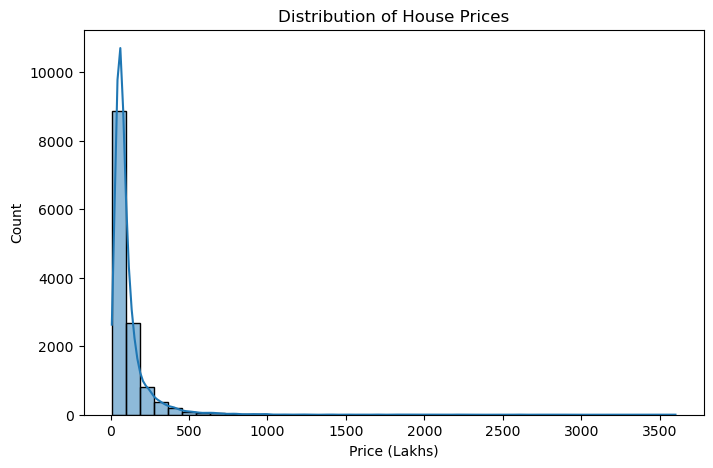

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=40, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakhs)")
plt.show()

## B. Relationship between house area and price

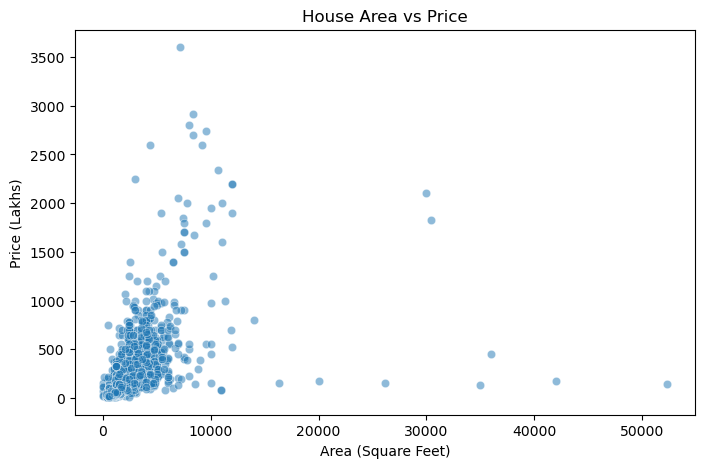

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="total_sqft",
    y="price",
    alpha=0.5
)
plt.title("House Area vs Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("Price (Lakhs)")
plt.show()

### C.Correlation between numerical features

Look for patterns, unusual records, and relationships. Larger houses often cost more, but location and property quality also matter.

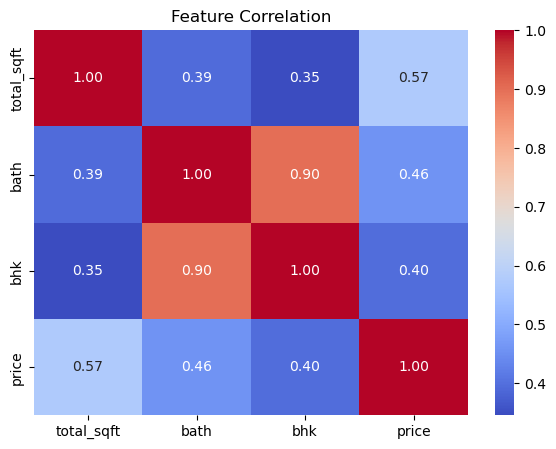

In [10]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[["total_sqft", "bath", "bhk", "price"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation")
plt.show()

## Prepare features and target

We will use four inputs:
- location
- total_sqft
- bath
- bhk
The target is price.

This creates an 80/20 split. The model learns from the training set and is evaluated on the unseen test set.

In [11]:
from sklearn.model_selection import train_test_split

X = df[["location", "total_sqft", "bath", "bhk"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 10560
Testing rows: 2640


# Train the first ML algorithm

Linear Regression. It estimates a relationship between property features and sale price.
Because location is text, we must encode it numerically. 
We will use a preprocessing pipeline to encode locations and then train the model.

The pipeline automatically converts the location category into numerical features before fitting the regression model.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

categorical_features = ["location"]
numeric_features = ["total_sqft", "bath", "bhk"]

preprocessor = ColumnTransformer([
    (
        "location",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )
], remainder="passthrough")

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


## Evaluate the model

Now We need to determine how close our predictions are to actual prices.



In [13]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 2), "lakhs")
print("RMSE:", round(rmse, 2), "lakhs")
print("R² score:", round(r2, 3))

MAE: 41.59 lakhs
RMSE: 86.5 lakhs
R² score: 0.578


MAE-Average absolute prediction error 
RMSE-Prediction error that penalizes large mistakes more heavily
R²-How well the model explains price variation relative to a mean baseline

## Compare actual prices with predictions

   Actual Price  Predicted Price
0          80.0        81.055824
1          75.0       235.965265
2          61.0        59.706680
3          62.0        82.691992
4          56.5        49.896312
5          27.0        -5.496389
6          58.0        58.755090
7          62.0        67.858746
8          75.0        97.227727
9          99.0       106.441169


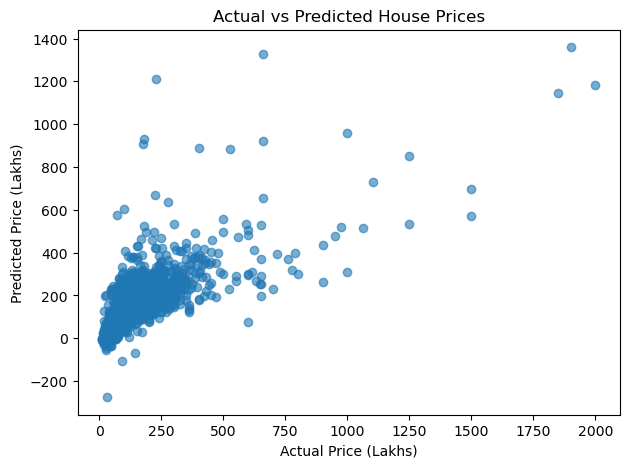

In [14]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions
})

print(comparison.head(10))

plt.figure(figsize=(7, 5))
plt.scatter(
    comparison["Actual Price"],
    comparison["Predicted Price"],
    alpha=0.6
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted House Prices")

plt.show()

Points closer to the diagonal line \(y=x\) represent more accurate predictions.

## Try a second algorithm — Random Forest
Random Forest can capture nonlinear relationships that Linear Regression may miss.

In [15]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([("preprocessor", preprocessor),("model",RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=42,n_jobs=-1))])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print(
    "Random Forest MAE:",
    round(mean_absolute_error(y_test, rf_predictions), 2),
    "lakhs"
)

print(
    "Random Forest RMSE:",
    round(
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        2
    ),
    "lakhs"
)

print("Random Forest R²:", round(
    r2_score(y_test, rf_predictions), 3
))

Random Forest MAE: 33.71 lakhs
Random Forest RMSE: 79.0 lakhs
Random Forest R²: 0.648


Compare both models on the same test set. Select the better model based on appropriate metrics, 
and check for overfitting before deciding which to deploy.

# Predict the price of a new house
Now use the trained model to estimate the price of a property.

In [16]:
new_house = pd.DataFrame([{
    "location": "Whitefield",
    "total_sqft": 1000,
    "bath": 3,
    "bhk": 4
}])

predicted_price = rf_model.predict(new_house)[0]

print(
    f"Estimated price: ₹{predicted_price:.2f} lakhs"
)

Estimated price: ₹146.96 lakhs


This example assumes "Whitefield" exists in the dataset. If the location is new, the model will still run, but its prediction may be unreliable because it has not learned that location's pricing patterns.
The output is an estimate, not a guaranteed market valuation.

# Save this model

Save the complete pipeline, including preprocessing, so you can reuse it without retraining.

In [17]:
import warnings
warnings.filterwarnings('ignore')
import streamlit as st
import pandas as pd
import joblib

#model = joblib.load("house_price_model.pkl")

st.title("House Price Prediction")
st.write("Estimate a house price using machine learning.")

location = st.text_input("Location", "Whitefield")
area = st.number_input(
    "Area in square feet", min_value=100, value=1200
)
bhk = st.number_input(
    "Number of bedrooms (BHK)",
    min_value=1, max_value=20, value=2
)
bath = st.number_input(
    "Number of bathrooms",
    min_value=1, max_value=20, value=2
)

if st.button("Predict Price"):
    house = pd.DataFrame([{
        "location": location,
        "total_sqft": area,
        "bath": bath,
        "bhk": bhk
    }])

    prediction = model.predict(house)[0]

    st.success(
        f"Estimated house price: ₹{prediction:.2f} lakhs"
    )

2026-10-30 13:44:17.512 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-30 13:44:18.389 
  command:

    streamlit run C:\Users\AMBIKA\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-30 13:44:18.391 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-30 13:44:18.391 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-30 13:44:18.392 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-30 13:44:18.393 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-30 13:44:18.394 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-30 13:44:18.394 Thread 'MainThread': m